# Robotics and computer projects (seam)

## 1. import libraries

In [25]:
import numpy
from pathlib import Path
import matplotlib.pyplot as plt
import time as time
from sklearn.metrics import confusion_matrix
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets,transforms
from torch.utils.data import DataLoader,random_split

## 2. load dataset and transform them

In [26]:
folder_data = Path('dataset')

try:
    if not folder_data.exists():
        raise FileNotFoundError
    
    # transform mode
    transform = transforms.Compose([
        transforms.Resize((96,96)),
        transforms.ToTensor(),

    ])


    dataset = datasets.ImageFolder(
        root='dataset/',
        transform=transform
    )
    print("dataset chargé avec succès")
except FileNotFoundError:
    print('dossiers introuvable,impossible de charger le dataset')

dataset chargé avec succès


In [27]:
n_train = int((0.8*len(dataset)))
n_test = len(dataset)-n_train

train_dataset,test_dataset = random_split(
    dataset,
    [n_train,n_test],
    generator=torch.Generator().manual_seed(42),
)


In [28]:
print(len(train_dataset))
print(len(test_dataset))

1600
400


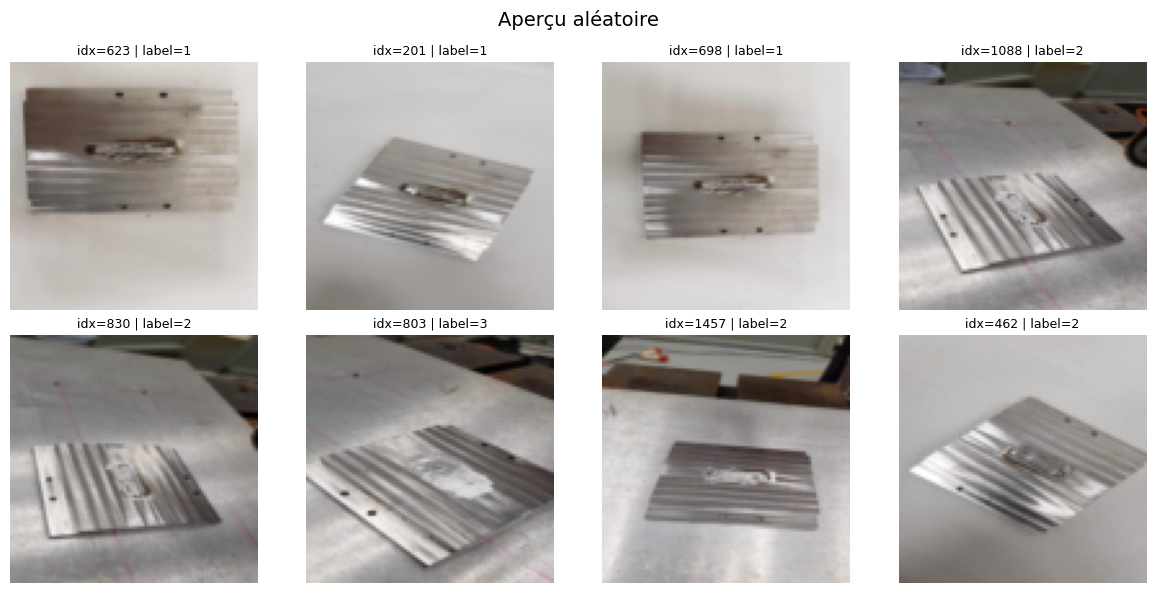

In [29]:
from utils import show_random_images
# train_dataset

show_random_images(dataset=train_dataset)

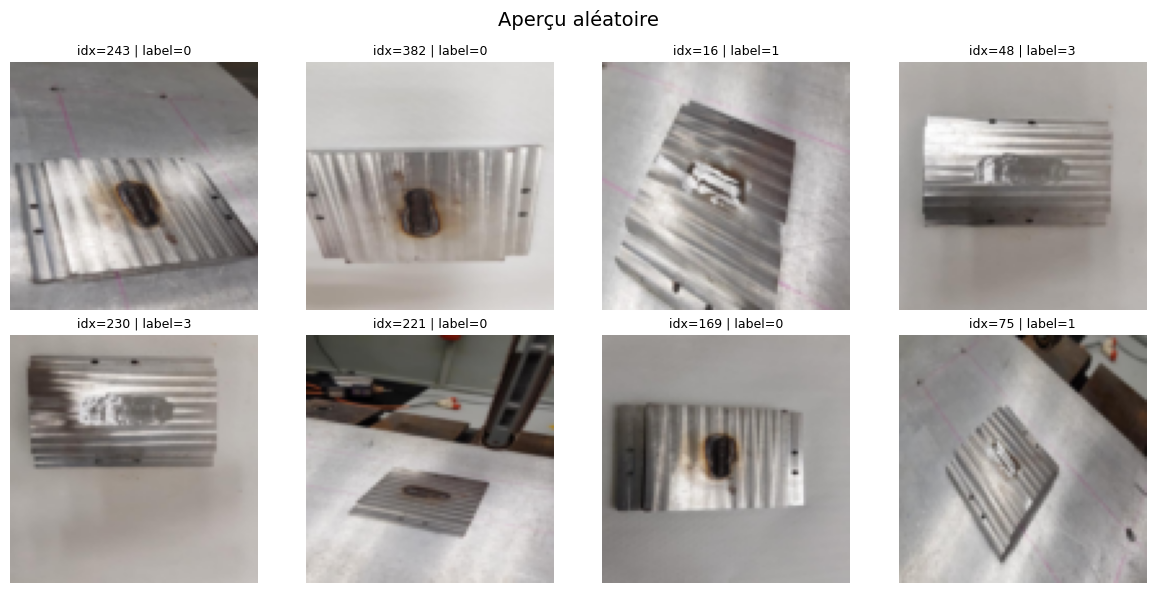

In [30]:
# show test dataset

show_random_images(dataset=test_dataset)

## 3. Dataloader

In [31]:
train_loader = DataLoader(dataset=train_dataset,batch_size=16,shuffle=True,num_workers=0,pin_memory=False)
test_loader = DataLoader(dataset=test_dataset,batch_size=16,shuffle=True,num_workers=0,pin_memory=False)
n_batch_train = len(train_loader)
print(f"n_batches = {n_batch}")
n_batch_test = len(test_loader)
print(f"n_batches of test = {n_batch_test}")


n_batches = 500
n_batches of test = 25


## 4. model preparations

In [32]:
from  architecture import VisionCNN

model = VisionCNN()
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr=0.001)

for parameter in model.parameters():
    print(parameter)

Parameter containing:
tensor([[[[-0.0223,  0.0451, -0.0216],
          [ 0.0984, -0.1062, -0.1583],
          [ 0.1735, -0.0669,  0.1826]],

         [[-0.1334,  0.1395,  0.1425],
          [-0.1875,  0.1043, -0.1423],
          [-0.0808, -0.1333, -0.1780]],

         [[ 0.0853, -0.1592, -0.1853],
          [-0.1742,  0.1420,  0.1632],
          [-0.0017,  0.0625, -0.0610]]],


        [[[-0.1505, -0.1088, -0.0741],
          [ 0.1303, -0.0761, -0.0837],
          [-0.0874,  0.0779, -0.0578]],

         [[ 0.0413,  0.1442, -0.1191],
          [-0.1092, -0.1451, -0.1450],
          [-0.1479, -0.0187,  0.1308]],

         [[-0.0234,  0.0466, -0.1572],
          [-0.0560, -0.0382, -0.0126],
          [-0.0398, -0.1530,  0.1526]]],


        [[[ 0.0528, -0.0681,  0.1711],
          [-0.0397, -0.1052, -0.1856],
          [ 0.1206, -0.0225, -0.0799]],

         [[ 0.1196,  0.0640, -0.0214],
          [ 0.0482,  0.0938,  0.1506],
          [-0.1777,  0.1609,  0.1373]],

         [[ 0.1871,  0

## 5. training model

In [34]:



epochs = 5
losses = []
CKPT = Path('models/checkpoints.pth')


# trainning
for epoch in range(epochs):
    start_time =time.time() 
    model.train() # fitting mode 
    for image,label in train_loader:
        optimizer.zero_grad()

        outpouts = model(image)
        loss = loss_fn(outpouts,label)

        
        loss.backward()
        optimizer.step()
        preds = torch.argmax(outpouts,dim=1)
        acc = (preds==label).float().mean().item()
        
    
    losses.append(loss.detach())
    print(f"Etape {epoch},perte = {loss.item():.4f},accuracy = {acc*100:.2f},time = {-start_time+time.time()} s")
    torch.save(model.state_dict(),CKPT)
    
    

Etape 0,perte = 0.1492,accuracy = 93.75,time = 269.6063895225525 s
Etape 1,perte = 0.3599,accuracy = 87.50,time = 222.80674505233765 s
Etape 2,perte = 0.0622,accuracy = 100.00,time = 194.51735830307007 s
Etape 3,perte = 0.1594,accuracy = 93.75,time = 227.51372265815735 s
Etape 4,perte = 0.0050,accuracy = 100.00,time = 302.33466362953186 s


## 6.predictions of model

In [43]:
model.eval()
all_preds = []
all_labels = []
with torch.no_grad():
    for image_test,label_test in test_loader:
        test_outpouts = model(image_test)
        loss =  loss_fn(test_outpouts,label_test)
        preds_test = torch.argmax(test_outpouts,dim=1)
        all_preds.append(preds_test)
        all_labels.append(label_test)
    
    
    all_preds = torch.cat(all_preds)
    all_labels =torch.cat(all_labels)
    acc_test = (all_preds==all_labels).float().mean().item()
    print(f"Precision sur le test = {acc_test*100:.2f}")
    print(f"matrice de confusion:\n{confusion_matrix(all_labels.numpy(),all_preds.long().numpy())}")


Precision sur le test = 96.25
matrice de confusion:
[[100   0   0   0]
 [  0 103   0   4]
 [  0   0  89  11]
 [  0   0   0  93]]


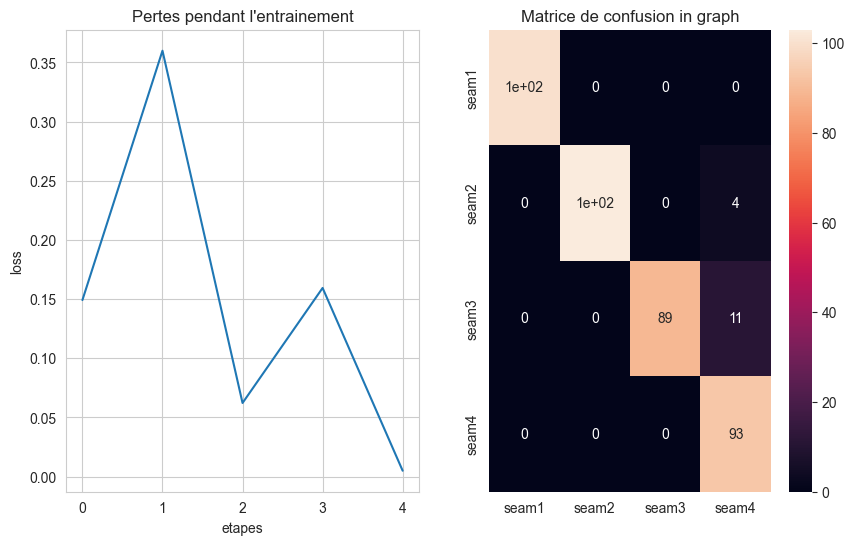

In [45]:
sns.set_style('whitegrid')
plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
plt.plot(losses)
plt.title("Pertes pendant l'entrainement")
plt.xlabel('etapes')
plt.ylabel('loss')

plt.subplot(1,2,2)
plt.title('Matrice de confusion in graph')
sns.heatmap(confusion_matrix(all_labels.numpy(),
all_preds.long().numpy()),
annot=True,xticklabels=dataset.classes,
yticklabels=dataset.classes)

plt.show()

## 7.save model

In [37]:
# Modeles folder 
save_folder= Path('models')
version = time.strftime("%Y%m%d_%H%M%S")
root = save_folder/f'model {version}.pth'

torch.save(model.state_dict(),root)